In [43]:
import pandas as pd
import matplotlib.pyplot as plt

# Dataset Selection and Reading

In [27]:
df = pd.read_csv('Spotify.csv')

# Data Understanding

In [28]:
df.head()

,ids,names,popularity,followers,genres,first_release,last_release,num_releases,num_tracks,monthly_listeners
0,68JRsR0O5ynf8xhu2jk2no,eqd,6,1974,NaN,2007,2023,10,2,1444.0
1,5VvZ6Br2O5ffnhkZt2HE8Q,チキンガーリックステーキ,3,140,NaN,2004,2010,12,2,231.0
2,2P3aLwJ41aRYkyFFw2FRM7,sam concepcion,45,168497,opm,2007,2023,20,1,583900.0
3,3ZzXi1Y1BvnvKJSVvzU2iP,vibemares,0,151,NaN,1996,1997,2,5,101.0
4,2ZC9B5qSrV48WOrOujZkNC,lantinor,0,1,NaN,2019,2019,1,12,0.0


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37000 entries, 0 to 36999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ids                37000 non-null  str    
 1   names              37000 non-null  str    
 2   popularity         37000 non-null  int64  
 3   followers          37000 non-null  int64  
 4   genres             12437 non-null  str    
 5   first_release      37000 non-null  int64  
 6   last_release       37000 non-null  int64  
 7   num_releases       37000 non-null  int64  
 8   num_tracks         37000 non-null  int64  
 9   monthly_listeners  36988 non-null  float64
dtypes: float64(1), int64(6), str(3)
memory usage: 2.8 MB


In [16]:
df.describe()

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000
50%,41.000000
75%,198.000000
max,16832.000000


In [30]:
df.isnull().sum()

ids                      0
names                    0
popularity               0
followers                0
genres               24563
first_release            0
last_release             0
num_releases             0
num_tracks               0
monthly_listeners       12
dtype: int64

# Data Transformation

In [31]:
df = df.drop(['num_tracks'], axis=1)


In [32]:
df

,ids,names,popularity,followers,genres,first_release,last_release,num_releases,monthly_listeners
0,68JRsR0O5ynf8xhu2jk2no,eqd,6,1974,NaN,2007,2023,10,1444.0
1,5VvZ6Br2O5ffnhkZt2HE8Q,チキンガーリックステーキ,3,140,NaN,2004,2010,12,231.0
2,2P3aLwJ41aRYkyFFw2FRM7,sam concepcion,45,168497,opm,2007,2023,20,583900.0
3,3ZzXi1Y1BvnvKJSVvzU2iP,vibemares,0,151,NaN,1996,1997,2,101.0
4,2ZC9B5qSrV48WOrOujZkNC,lantinor,0,1,NaN,2019,2019,1,0.0
...,...,...,...,...,...,...,...,...,...
36995,4TMRBn1plXqjzUY7o3yOXQ,phil maggio,1,228,NaN,2011,2020,8,175.0
36996,4bl3Yv4KUEz0eeq2CufBtP,francesca beghe,8,186,NaN,1991,2022,7,2794.0
36997,1UDOAzRwVvdUPrFN5Whz8p,zelf,0,1,NaN,2018,2019,15,0.0
36998,4KiROF7429B2u0msF92ueV,electryxeed,1,316,NaN,2011,2017,3,391.0


# Handling Null Values

In [33]:
df.isnull().sum()

ids                      0
names                    0
popularity               0
followers                0
genres               24563
first_release            0
last_release             0
num_releases             0
monthly_listeners       12
dtype: int64

In [36]:
df['monthly_listeners'] = df['monthly_listeners'].fillna(df['monthly_listeners'].mean())
df

,ids,names,popularity,followers,genres,first_release,last_release,num_releases,monthly_listeners
0,68JRsR0O5ynf8xhu2jk2no,eqd,6,1974,NaN,2007,2023,10,1444.0
1,5VvZ6Br2O5ffnhkZt2HE8Q,チキンガーリックステーキ,3,140,NaN,2004,2010,12,231.0
2,2P3aLwJ41aRYkyFFw2FRM7,sam concepcion,45,168497,opm,2007,2023,20,583900.0
3,3ZzXi1Y1BvnvKJSVvzU2iP,vibemares,0,151,NaN,1996,1997,2,101.0
4,2ZC9B5qSrV48WOrOujZkNC,lantinor,0,1,NaN,2019,2019,1,0.0
...,...,...,...,...,...,...,...,...,...
36995,4TMRBn1plXqjzUY7o3yOXQ,phil maggio,1,228,NaN,2011,2020,8,175.0
36996,4bl3Yv4KUEz0eeq2CufBtP,francesca beghe,8,186,NaN,1991,2022,7,2794.0
36997,1UDOAzRwVvdUPrFN5Whz8p,zelf,0,1,NaN,2018,2019,15,0.0
36998,4KiROF7429B2u0msF92ueV,electryxeed,1,316,NaN,2011,2017,3,391.0


# Insight Generation

In [51]:
insights = df.groupby('first_release')['monthly_listeners'].mean().head(10)
insights

first_release
-1         4337.799508
 1877        47.000000
 1883        92.000000
 1888       467.000000
 1899    113575.666667
 1900      7997.750000
 1901      2690.500000
 1909     24653.000000
 1921     97749.000000
 1924      8949.000000
Name: monthly_listeners, dtype: float64

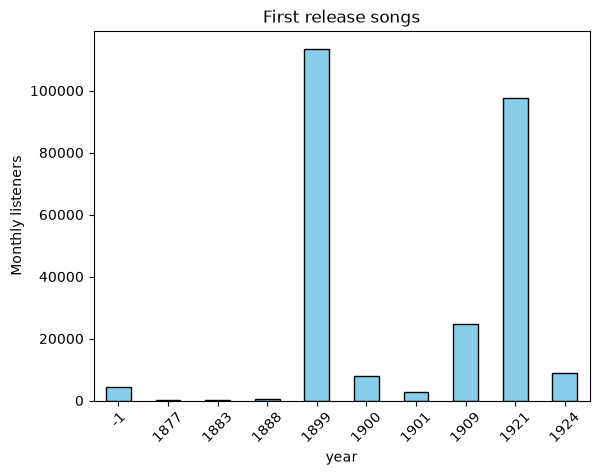

In [55]:
insights.head(10).plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('First release songs')
plt.xlabel('year')
plt.ylabel('Monthly listeners')
plt.xticks(rotation=45)
plt.show()